# Business Survival in Ireland 
#  Module: Statistics for Data Analytics - CA1
**Student name:** Valeria Cantu Angel
**Student ID:** 2026679 **Lecturer:** Taufique Ahmed

**Dataset:** CSO BRA36 - Enterprise Survival NACE Rev. 2 (data.gov.ie)

**GitHub repository:** https://github.com/2026679-arch/Statistical-Tech-679

# Research objective

To explore enterprise births and business survival in Ireland. 

# Setup
We import the libraries used throughout the analysis.

In [196]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [197]:
# Load the original data
df = pd.read_csv("BRA36.20261013T001012.csv", encoding="utf-8-sig")

#Inspect the dataset
print("Dataset shape:", df.shape)
df.info()

df.head()

Dataset shape: (80784, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80784 entries, 0 to 80783
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Statistic Label  80784 non-null  object 
 1   Year             80784 non-null  int64  
 2   Employment Size  80784 non-null  object 
 3   Activity         80784 non-null  object 
 4   UNIT             80784 non-null  object 
 5   VALUE            61434 non-null  float64
dtypes: float64(1), int64(1), object(4)
memory usage: 3.7+ MB


,Statistic Label,Year,Employment Size,Activity,UNIT,VALUE
0,Enterprise births in reference year,2019,All persons engaged size classes,Mining and Quarrying (B),Number,27.0
1,Enterprise births in reference year,2019,All persons engaged size classes,Manufacturing (C),Number,1237.0
2,Enterprise births in reference year,2019,All persons engaged size classes,"Electricity, Gas, Steam and Air Conditioning S...",Number,57.0
3,Enterprise births in reference year,2019,All persons engaged size classes,"Water Supply; Sewerage, Waste Management and R...",Number,57.0
4,Enterprise births in reference year,2019,All persons engaged size classes,Construction (F),Number,5151.0


## Data Preparation

Three numerical measures are selected: enterprise births,
persons engaged at birth and enterprises surviving one year.

Broad economic sectors are retained using the all-size total.
Detailed subsectors and individual size categories are not
added to these totals, avoiding double counting.

The data were obtained from the CSO BRA36 Enterprise
Survival dataset (Central Statistics Office, n.d.).

In [198]:
# Define the numerical measures and their shorter names
measure_names = {"Enterprise births in reference year":"Births","Persons engaged by enterprise births in reference year":"Persons engaged at birth","Enterprise births surviving one year to reference year":"One-year survivors"}

# Check that the required measures exist
assert set(measure_names).issubset(df["Statistic Label"].unique())

# Identify broad economic sectors
sector_endings = ("(B)", "(C)", "(D)", "(E)", "(F)", "(G)","(H)", "(I)", "(J)", "(K)", "(L)", "(M)","(N)", "(P)", "(Q)", "(R)")

# Select the measures, broad sectors and all-size totals
prepared_data = df.loc[df["Statistic Label"].isin(measure_names) & df["Activity"].str.endswith(sector_endings, na=False) & df["Employment Size"].eq("All persons engaged size classes")
].copy()

# Assign shorter measure names
prepared_data["Measure"] = (prepared_data["Statistic Label"].map(measure_names))

print("Selected measures:", prepared_data["Measure"].nunique())
print("Selected sectors:", prepared_data["Activity"].nunique())
print("Selected records:", len(prepared_data))

Selected measures: 3
Selected sectors: 16
Selected records: 288


### Birth Cohort Alignment

One-year survivors recorded in a reference year belong
to enterprises born in the previous year.

The measures are aligned by birth cohort. Cohorts from
2019 to 2023 are retained because their following-year
survival records fall within the available period.

In [199]:
# Initially assign the reference year as the birth cohort
prepared_data["Birth cohort"] = prepared_data["Year"]

# Assign survivors to the previous year's birth cohort
survival_rows = prepared_data["Measure"].eq("One-year survivors")

prepared_data.loc[survival_rows, "Birth cohort"] = (prepared_data.loc[survival_rows, "Year"] - 1)

# Check that each measurement has a unique key
assert not prepared_data.duplicated(
    ["Birth cohort", "Activity", "Measure"]).any()

# Arrange the three measures into separate columns
analysis_table = prepared_data.pivot(index=["Birth cohort", "Activity"],columns="Measure",values="VALUE").reset_index()

analysis_table.columns.name = None

# Retain cohorts with birth-year and follow-up coverage
analysis_table = analysis_table.loc[analysis_table["Birth cohort"].between(2019, 2023)].copy()

# Arrange the columns
analysis_table = analysis_table[["Birth cohort","Activity","Births","Persons engaged at birth","One-year survivors"]].sort_values(["Birth cohort", "Activity"]).reset_index(drop=True)

# Treat the cohort and economic activity as categorical groups
analysis_table["Birth cohort"] = (analysis_table["Birth cohort"].astype("category"))

analysis_table["Activity"] = (analysis_table["Activity"].astype("category"))

print("Prepared dataset shape:", analysis_table.shape)
analysis_table.head(10)

Prepared dataset shape: (80, 5)


,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors
0,2019,Accommodation and Food Service Activities (I),1937.0,10317.0,1619.0
1,2019,Administrative and Support Service Activities (N),1528.0,2840.0,1261.0
2,2019,"Arts, Entertainment and Recreation (R)",924.0,1425.0,692.0
3,2019,Construction (F),5151.0,7954.0,4111.0
4,2019,Education (P),896.0,1399.0,707.0
5,2019,"Electricity, Gas, Steam and Air Conditioning S...",57.0,36.0,55.0
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0
7,2019,Human Health and Social Work Activities (Q),1287.0,4004.0,1067.0
8,2019,Information and Communication (J),1772.0,4606.0,1497.0
9,2019,Manufacturing (C),1237.0,1886.0,1029.0


In [200]:
#Calculate one-year business survival rate

analysis_table ["Survival Rate(%)"] = (analysis_table["One-year survivors"] / analysis_table["Births"]) * 100

#display the results
analysis_table.head(10)

,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors,Survival Rate(%)
0,2019,Accommodation and Food Service Activities (I),1937.0,10317.0,1619.0,83.582860
1,2019,Administrative and Support Service Activities (N),1528.0,2840.0,1261.0,82.526178
2,2019,"Arts, Entertainment and Recreation (R)",924.0,1425.0,692.0,74.891775
3,2019,Construction (F),5151.0,7954.0,4111.0,79.809746
4,2019,Education (P),896.0,1399.0,707.0,78.906250
5,2019,"Electricity, Gas, Steam and Air Conditioning S...",57.0,36.0,55.0,96.491228
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0,NaN
7,2019,Human Health and Social Work Activities (Q),1287.0,4004.0,1067.0,82.905983
8,2019,Information and Communication (J),1772.0,4606.0,1497.0,84.480813
9,2019,Manufacturing (C),1237.0,1886.0,1029.0,83.185125


In [201]:
print(analysis_table.columns.tolist())

['Birth cohort', 'Activity', 'Births', 'Persons engaged at birth', 'One-year survivors', 'Survival Rate(%)']


In [202]:
# Summary of survival rates

print(analysis_table["Survival Rate(%)"].describe())

# Check missing values

print("\nMissing values:")
print(analysis_table["Survival Rate(%)"].isnull().sum())

# Check minimum and maximum

print("\nMinimum survival rate:",
      analysis_table["Survival Rate(%)"].min())

print("\nMaximum survival rate:",
      analysis_table["Survival Rate(%)"].max())

count    78.000000
mean     80.589202
std       4.953014
min      66.666667
25%      77.726020
50%      80.673458
75%      83.052953
max      96.969697
Name: Survival Rate(%), dtype: float64

Missing values:
2

Minimum survival rate: 66.66666666666666

Maximum survival rate: 96.96969696969697


In [203]:
# Identify missing survival rate observations

missing_data = analysis_table[analysis_table["Survival Rate(%)"].isnull()]

#Display missing observations

display(missing_data)

,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors,Survival Rate(%)
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0,NaN
22,2020,Financial and Insurance Activities (K),NaN,3681.0,1559.0,NaN


In [204]:
print("Missing births:")
print(analysis_table["Births"].isnull().sum())

print("\nZero births:")
print((analysis_table["Births"] == 0).sum())

Missing births:
2

Zero births:
0


In [205]:
#Identify observations with missing business births 

missing_births = analysis_table[analysis_table["Births"].isnull()]

display(missing_births)

,Birth cohort,Activity,Births,Persons engaged at birth,One-year survivors,Survival Rate(%)
6,2019,Financial and Insurance Activities (K),NaN,1640.0,926.0,NaN
22,2020,Financial and Insurance Activities (K),NaN,3681.0,1559.0,NaN


In [206]:
#Check missing values in all numerical variables

print(analysis_table[["Births", "Persons engaged at birth","One-year survivors","Survival Rate(%)",]].isnull().sum())

Births                      2
Persons engaged at birth    5
One-year survivors          0
Survival Rate(%)            2
dtype: int64


# Missing Values and Data Quality

The prepared dataset contains 80 observations distributed across 16 economic sectors and five cohorts based on the year of establishment (2019-2023)

Two missing values were identified in the "Enterprise Births" variable, both pertaining to the financial and insurance activities sector, it was not possible to calculate the first year survival rate for these observations.

However, five missing values were detected in the "Persons Engaged at Birth" variable, these do not directly affect the calculation of enterprise survival rates.

The missing values were left as they are rather than being replaced with zeros or estimates to avoid introducing information. Statistical calculations related to survival rates exclude observations for which the necessary data are unavailable.

# Sectoral coverage 

For activies related to finance and insurance data on the number of new business "births" are unavailable for the years 2019 and 2020. Consequently, the average survival rate in these sectors is calculated based on three cohorts, whereas five cohorts are used for the other sectors.
The aggregated survival rates by cohort cover 15 sector for the 2019 - 2020 period and 16 sectors for 2021 - 2023 period. Therefore differences regarding the cohorts may reflect variations in both the survival rate and the sectoral coverage.

In [207]:
# Select the numerical variables
descriptive_columns = ["Births", "Persons engaged at birth", "One-year survivors", "Survival Rate(%)"]

#Calculate descriptive stats.
descriptive_summary = (analysis_table[descriptive_columns].describe().T)

#Calculate skewness for each variable
descriptive_summary["skewness"] = (analysis_table[descriptive_columns].skew())

#Display the summary table
display(descriptive_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness
Births,78.0,2341.24,2382.94,25.00,1241.75,1947.00,2643.00,12326.00,2.43
Persons engaged at birth,75.0,3619.20,3393.17,21.00,1436.50,2768.00,5026.00,15152.00,1.36
One-year survivors,80.0,1839.85,1801.10,18.00,947.00,1539.00,2116.25,9387.00,2.27
Survival Rate(%),78.0,80.59,4.95,66.67,77.73,80.67,83.05,96.97,0.56


# Selection of Descriptive Charts

A horizontal bar chart represents the average survival rate by economic sector and allos for the inclusion of numerous labels for these sectors. The averages by economic sector assign equal weight to the survival rate of each individual cohort.
A line chart displays the cumulative survival rates for various birth cohorts. These survival rate are weighted according to the number of births in each sector and should be interpreted with consideration for the coverage limitations of those sectors.
A histogram illustrates the distribution of survival rates by sector and cohort.

In [208]:
#Calculate average survival rate by economic sector

sector_survival = (analysis_table.groupby("Activity", observed=True)["Survival Rate(%)"].mean().sort_values())

print(sector_survival)

Activity
Construction (F)                                                            76.369132
Real Estate Activities (L)                                                  77.357909
Financial and Insurance Activities (K)                                      77.851454
Mining and Quarrying (B)                                                    78.660804
Arts, Entertainment and Recreation (R)                                      79.170691
WholeSale and Retail Trade; Repair of Motor Vehicles and Motorcycles (G)    79.199984
Transportation and Storage (H)                                              79.633286
Manufacturing (C)                                                           79.776692
Administrative and Support Service Activities (N)                           79.813155
Education (P)                                                               80.155850
Information and Communication (J)                                           80.239665
Professional, Scientific and Technical Activi

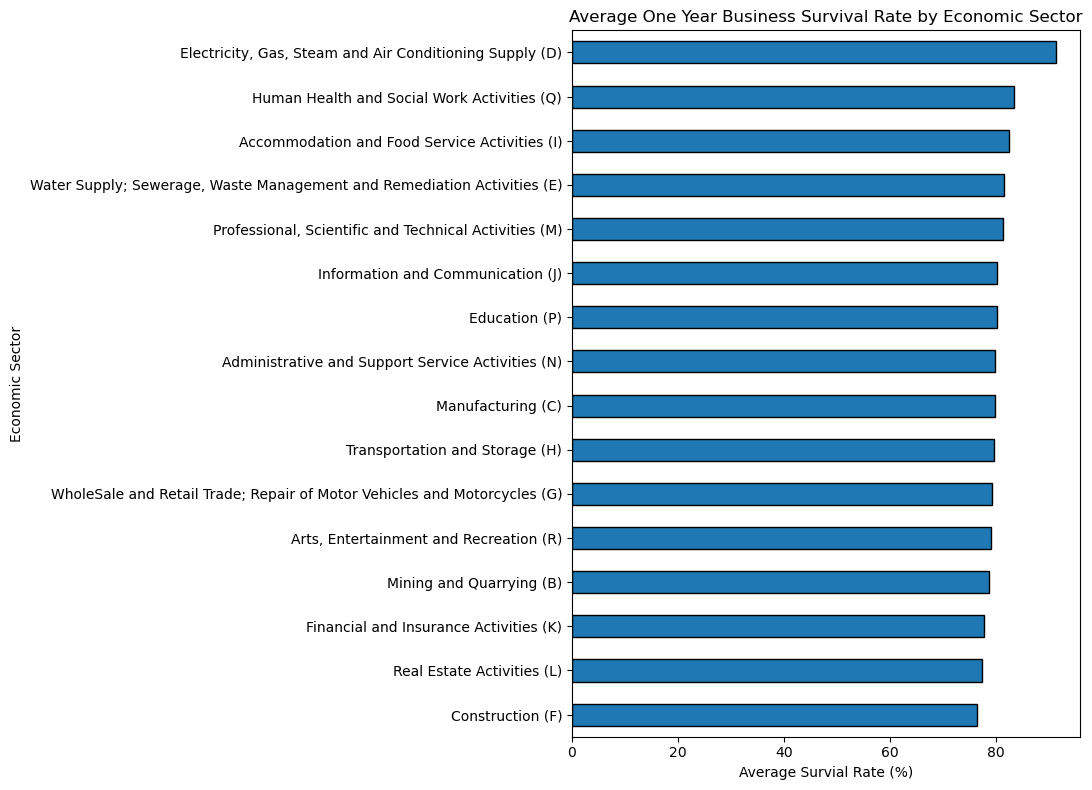

In [209]:
#Create the first statistical graph

plt.figure(figsize=(11, 8))

sector_survival.plot(kind="barh",edgecolor="black")
plt.title("Average One Year Business Survival Rate by Economic Sector")

plt.xlabel("Average Survial Rate (%)")
plt.ylabel("Economic Sector")

plt.tight_layout()
plt.show()

In [210]:
#Identify the highest and lowest survival rates

print("Lowest survival rate:")
print(sector_survival.head(3))

print("\nHighest survival rate:")
print(sector_survival.tail(3))

Lowest survival rate:
Activity
Construction (F)                          76.369132
Real Estate Activities (L)                77.357909
Financial and Insurance Activities (K)    77.851454
Name: Survival Rate(%), dtype: float64

Highest survival rate:
Activity
Accommodation and Food Service Activities (I)              82.560032
Human Health and Social Work Activities (Q)                83.351188
Electricity, Gas, Steam and Air Conditioning Supply (D)    91.317174
Name: Survival Rate(%), dtype: float64


# Business Survival Across Economic Sectors

The analysis reveals variations in average one year business rates across the 16 economic sectors examined. The electricity, gas, stream, and air conditioning supply sector recorded the highest average survival rate at 91.31%, while the construction sector showed the lowest 76.36%. 

The gap between these sectors was approximately 14.95 percentage points. Real estate activities, as well as financial and insurance activities, also exhibited relatively low average survival rate: 77.35% and 77.85% respectively.

These findings indicate that business survival patterns vary according to economic activity. However, the results reflect average survival rates at the sectoral level based on available cohorts of newly created businesses and do not determine the underlying causes of these differences.

In [211]:
#Remove observations with missing values in the variables

valid_data = analysis_table.dropna(subset=["Births", "One-year survivors"]).copy()

#Calculate survival rate by birth cohort

cohort_survival = (valid_data.groupby("Birth cohort", observed=True)[["Births", "One-year survivors"]].sum())

cohort_survival["Survival Rate(%)"] = (cohort_survival["One-year survivors"] / cohort_survival["Births"]) * 100

In [212]:
display(cohort_survival)

,Births,One-year survivors,Survival Rate(%)
Birth cohort,,,
2019,24193.0,19674.0,81.321043
2020,32497.0,26054.0,80.173554
2021,35586.0,27673.0,77.763727
2022,45380.0,36111.0,79.574703
2023,44961.0,35191.0,78.270056


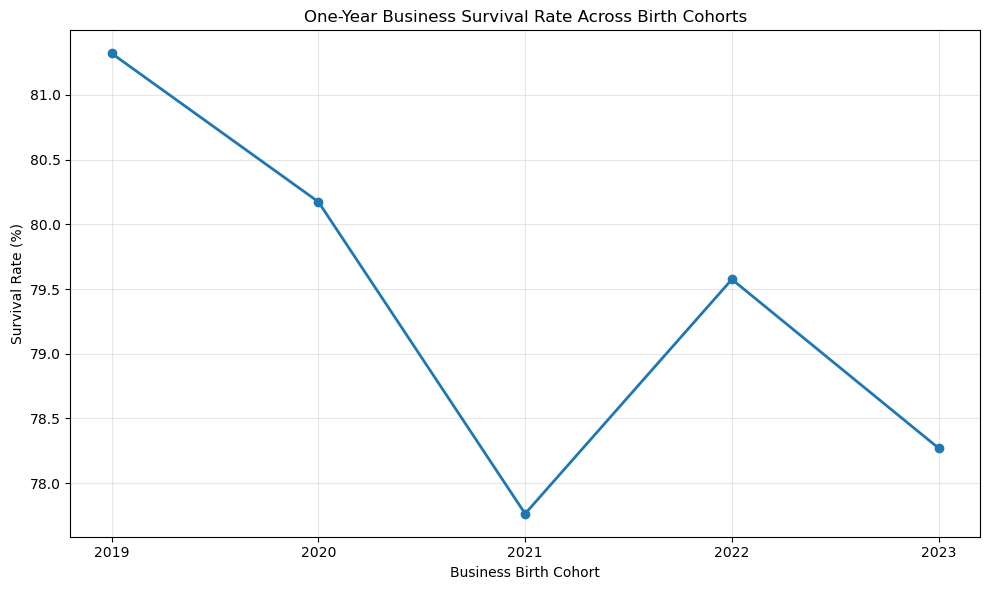

In [213]:
# Graph 2: Survival rate across birth cohorts

plt.figure(figsize=(10, 6))

plt.plot(cohort_survival.index.astype(str), cohort_survival["Survival Rate(%)"], marker="o",linewidth=2)

plt.title("One-Year Business Survival Rate Across Birth Cohorts")
plt.xlabel("Business Birth Cohort")
plt.ylabel("Survival Rate (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Business Survival Trends

An analysis of first year business survival rates, covering founding cohorts from 2019 to 2023 reveals a variable pattern. The 2019 cohort recorded the highest survival rate around 81.32% while the lowest was observed in 2021 at around 77.76%

Following the decline in 2021, survival rates partially recovered in 2022, only to decrease again in 2023, these findings indicate that business survival rates varied across the five cohorts, showing no consistent upward or downward trend.

In [214]:
#Display exact survival rates by birth cohort

print(cohort_survival["Survival Rate(%)"].round(2))

Birth cohort
2019    81.32
2020    80.17
2021    77.76
2022    79.57
2023    78.27
Name: Survival Rate(%), dtype: float64


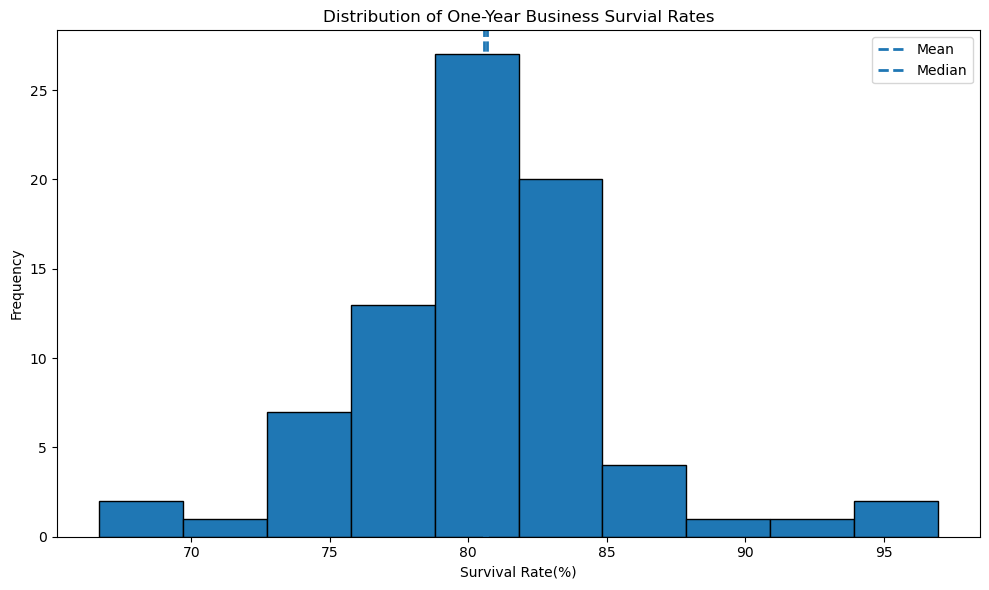

In [215]:
#Graph 3: Distribution of business survival rates

plt.figure(figsize=(10,6))

plt.hist(analysis_table["Survival Rate(%)"].dropna(), bins=10, edgecolor="black")

plt.axvline(analysis_table["Survival Rate(%)"].mean(), linestyle="--", linewidth=2, label="Mean")

plt.axvline(analysis_table["Survival Rate(%)"].median(), linestyle="--", linewidth=2, label="Median")

plt.title("Distribution of One-Year Business Survial Rates")
plt.xlabel("Survival Rate(%)")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

In [216]:
#Calculate distribution

survival_rates = analysis_table["Survival Rate(%)"].dropna()

print("Mean:", survival_rates.mean())
print("Median:", survival_rates.median())
print("Standard deviation:", survival_rates.std())

print("\nSkewness:", survival_rates.skew())

Mean: 80.58920236722805
Median: 80.67345783814375
Standard deviation: 4.953014407893164

Skewness: 0.5638489419173234


# Distribution and Skewness Analysis

The one year business survival rates has a mean of 80.59% and a median of 80.67%, the standard deviation is 4.95% which implies that the variance of the dataset is not particularly high, given the sample size of 78. The skewness coefficient is 0.564, indicating a degree of positive skewness in the distribution of the survival rate. This means there is a long tail on the right side of the distribution.

Although the histogram shows a concentration of observations around 80% 
, the distribution is not perfectly symmetrical. These results provide an initial basis for examining the suitability of a normal distribution in the next stage of the analysis.

# Normal distribution

The normal distribution is fitted to available data on survival rates for specific sectors and age groups, based on their mean and standard deviation.
This model is used to calculate probabilities regarding survival rates for sectors and age groups not the survival of any individual company. The suitability of the model is evaluated rather than simply assumed.

In [217]:
#Calculate Z-score for an 85% survival rate

mean_survival = survival_rates.mean()
std_survival = survival_rates.std()

value = 85

z_score = (value - mean_survival) / std_survival

print("Mean:", mean_survival)
print("Standard deviation:", std_survival)
print("Z-score:", z_score)

Mean: 80.58920236722805
Standard deviation: 4.953014407893164
Z-score: 0.890527922903447


In [218]:
#Calculate probability using Normal Distribution

probability = stats.norm.cdf(85, loc=mean_survival, scale=std_survival)

print("Probability below 85%:", probability)
print("Percentage:", probability * 100)

Probability below 85%: 0.8134087590336472
Percentage: 81.34087590336472


In [219]:
#Calculate the fitted normal probability above 85%

probability_above = stats.norm.sf(85, loc=mean_survival, scale=std_survival)

print("Fitted Normal probability above 85%:", probability_above)
print("Percentage:", probability_above * 100)



Fitted Normal probability above 85%: 0.18659124096635288
Percentage: 18.65912409663529


In [220]:
#Compare the fitted normal model with the observed data
observed_below_85 = (survival_rates < 85).mean()

normal_below_85 = stats.norm.cdf(85, loc=mean_survival, scale=std_survival)

print(f"Observed proportion below 85%: {observed_below_85: .2%}")
print(f"Fitted Normal probability below 85%: {normal_below_85: .2%}")

Observed proportion below 85%:  91.03%
Fitted Normal probability below 85%:  81.34%


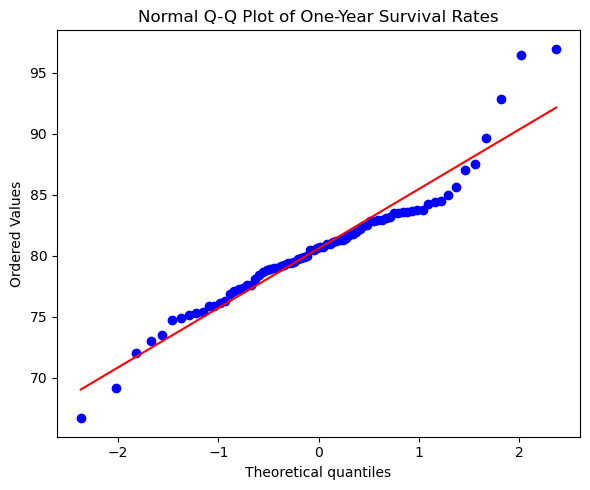

In [221]:
#Compare the observed rates with Normal theoretical quantiles
fig, ax = plt.subplots(figsize=(6, 5))

stats.probplot(survival_rates, dist="norm", plot=ax)

ax.set_title("Normal Q-Q Plot of One-Year Survival Rates")
plt.tight_layout()
plt.show()

SciPy's probplot function was used to compare the
observed rates with theoretical Normal quantiles
(SciPy, n.d.-d).

# Evaluation of the normal approximation

According to the normal model, the probability of obtaining a survival rate below 85% is estimated at 81.34% whereas the observed value is 91.03%

This discrepancy suggests that the normal model fails to accurately fit the observed value at this threshold. Futhermore, the skewness and the bounded nature of survival rates influence this approximation. Consequently, the normal model is considered only a descriptive approximation.

Normal probabilities were calculated using SciPy's
cumulative distribution and survival functions
(SciPy, n.d.-b).

In [222]:
# Binomal Distribution for calculate the overall business survival probability

binomial_data = analysis_table.dropna(subset=["Births", "One-year survivors"]).copy()

total_births = binomial_data["Births"].sum()

total_survivors = binomial_data ["One-year survivors"].sum()

p = total_survivors / total_births

print("Total business births:", total_births)
print("Total one-year survivors:", total_survivors)
print("Survival probability (p):", p)
print("Survival percentage:", p * 100)

Total business births: 182617.0
Total one-year survivors: 144703.0
Survival probability (p): 0.792385155817914
Survival percentage: 79.2385155817914


# Binomial Model and its Assumptions

Let X be the number of businesses that survive the first year in the assumed set of 100 new businesses. There are only two options for each business survival or non survival. The assumptions include independence of the results and the same probability of survival p = 0.792385. Probability of exaclty k survivors: 

\[
p(x=k)=\binom{n}{k}p^k(1-p)^{n-k}
\]
The expected number of survivors equals np, while the variance is np (1-p).
These assumptions can be considered oversimplified. Survival rates differ from industry to industry, generation to generation, and economic conditions can make the outcomes of different companies dependent, therefore the probabilities obtained are conditional examples not forecasts.

In [223]:
#Binomial Distribution probability of business survival in a sample of 100

from scipy.stats import binom
n = 100

#Expected number of survivors
expected_survivors = n * p

#Probability of exactly 80 survivors
prob_exactly_80 = binom.pmf(80, n, p)

#Probability of at least 80 survivors
prob_at_least_80 = binom.sf(79, n, p)

print ("Sample size:", n)
print ("Expected survivors:", expected_survivors)
print ("Probability of exactly 80 survivors:", prob_exactly_80)
print ("Probability of at least 80 survivors:", prob_at_least_80)


Sample size: 100
Expected survivors: 79.2385155817914
Probability of exactly 80 survivors: 0.09754967704655539
Probability of at least 80 survivors: 0.4839350330218629


# Binomial Distribution Analysis

The binomial distribution was applied using an estimated business survival probability of 79.24%, calculated  based on the total number of businesses created and the number that survived their fisrt year.

A hypothetical sample of 100 businesses was selected. The expected number of survivng businesses was approximately 79.24.
The probability that exactly 80 businesses would survive was approximately 9.75% while the probability that at least 80 businesses would survive was approximately 48.39%

These results illustrate how the binomial distribution can be used to estimate the probability of various business survival scenarios within a given sample, assuming that the outcomes are independent and the probability of survival remains constant.

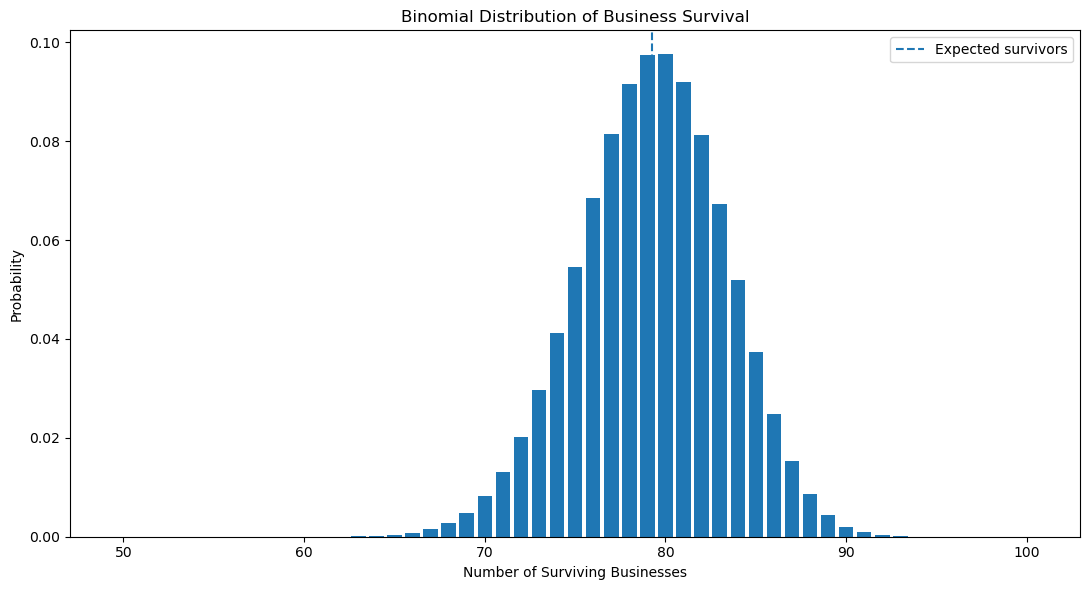

In [224]:
#Graph Binomial Distribution

x = np.arange(50, 101)

binomial_probabilities = binom.pmf(x, n, p)

plt.figure(figsize=(11, 6))

plt.bar(x, binomial_probabilities)

plt.axvline(expected_survivors, linestyle="--", label="Expected survivors")

plt.title("Binomial Distribution of Business Survival")
plt.xlabel("Number of Surviving Businesses")
plt.ylabel("Probability")
plt.legend()

plt.tight_layout()
plt.show()

In [225]:
# Effect of sample size on Binomial Distribution

sample_sizes =[30, 100, 500]

for sample in sample_sizes:
    expected = sample * p
    standard_deviation = np.sqrt(sample * p * (1 - p))

    print("\nSample size:", sample)
    print("Expected survivors:", expected)
    print("Standard deviation:", standard_deviation)


Sample size: 30
Expected survivors: 23.77155467453742
Standard deviation: 2.2215597267955736

Sample size: 100
Expected survivors: 79.2385155817914
Standard deviation: 4.055994584036499

Sample size: 500
Expected survivors: 396.192577908957
Standard deviation: 9.069479606276596


# Effect of Sample Size on Binomial Distribution

The effect of sample size was examined using three different sizes: 30, 100 and 500 firms, the expected number of survivors increased from approximately 23.77 to 79.24 and 396.19 respectively.

The standard deviation also increased as the sample size grew, however the relative standard deviation decreased, indicating lower proportional variability in larger samples.
These results demonstrate that larger samples yield more stable estimates of the business survival proportion, assuming a constant probability of survival and independent outcomes.



The probabilities were calculated using SciPy's
Binomial probability mass function and survival
function (SciPy, n.d.-a).

# Poisson Distribution

Can be a model used to describe the probability of an event occuring a specific number of times within a fixed interval of time or space. This model is useful when events are infrequent or unusual. The Poisson distribution helps in understanding the frequency of such events and in making predictions about them. The number of new businesses created in a sector over the course of a year constitutes a specific count, the Poisson distribution serves as a fundamental model for this type of tally. The parameter lambda represents the expected number of new businesses to be formed annually in each sector, calculated based on the average of available data. The model assumes that events are independent of one another and that the rate at which they pass remains constant throughout the observation period. Both the mean and the variance are equal to lambda.

In [226]:
#Poisson Distribution remove missing birth observations

poisson_data = analysis_table["Births"].dropna()

#Calculate average number of number births

lambda_value = poisson_data.mean()

print("Number of observations:", len(poisson_data))
print("Mean business births (Lambda):", lambda_value)

Number of observations: 78
Mean business births (Lambda): 2341.24358974359


In [227]:
# Poisson distribution probability calculations
from scipy.stats import poisson

In [228]:
#Round lambda to the nearest whole number
k = round(lambda_value)

In [229]:
#Probability of exactly k businss births
prob_exact = poisson.pmf(k, lambda_value)

In [230]:
#Probability of fewer than k business births
prob_below = poisson.cdf(k - 1, lambda_value)

#Probability of k or more business births
prob_at_least = poisson.sf(k - 1, lambda_value)

print("Lambda:", lambda_value)
print("Number of births", k)

print("Probability of exactly k:", prob_exact)
print("Probability below k:", prob_below)
print("Probability of at least k:", prob_at_least)

Lambda: 2341.24358974359
Number of births 2341
Probability of exactly k: 0.008244957013694232
Probability below k: 0.49524324236690276
Probability of at least k: 0.5047567576330971


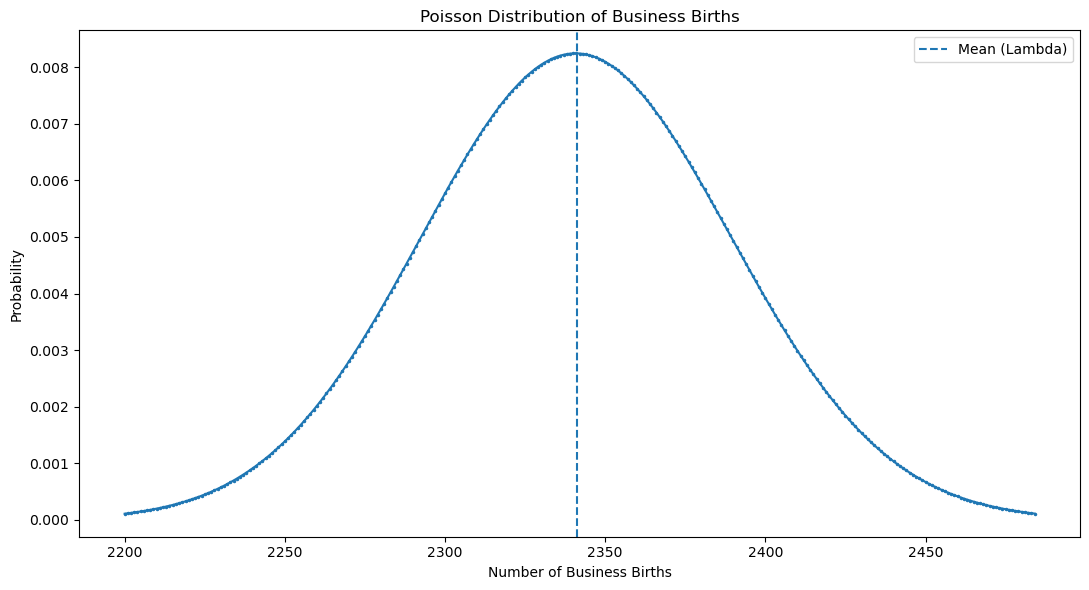

In [231]:
#Graph Poisson Distribution

x =np.arange(2200, 2485)

poisson_probabilities = poisson.pmf(x, lambda_value)

plt.figure(figsize=(11, 6))
plt.plot(x, poisson_probabilities, marker= ".", markersize = 3)

plt.axvline(lambda_value, linestyle = "--", label = "Mean (Lambda)")

plt.title("Poisson Distribution of Business Births")
plt.xlabel("Number of Business Births")
plt.ylabel("Probability")
plt.legend()

plt.tight_layout()
plt.show()


In [232]:
#Check Poisson distribution assumptions

actual_mean = poisson_data.mean()
actual_variance = poisson_data.var()
actual_std = poisson_data.std()

theoretical_variance = lambda_value
theoretical_std = np.sqrt(lambda_value)

print("Actual mean:", actual_mean)
print("Actual variance:", actual_variance)
print("Actual standard deviation:", actual_std)

print("\nTheoretical Poisson variance:", theoretical_variance)
print("Theoretical Poisson standard deviation:", theoretical_std)

print("\nVariance-to-mean ratio:",
      actual_variance / actual_mean)

Actual mean: 2341.24358974359
Actual variance: 5678393.069763566
Actual standard deviation: 2382.937907240465

Theoretical Poisson variance: 2341.24358974359
Theoretical Poisson standard deviation: 48.38639880941327

Variance-to-mean ratio: 2425.3747429952205


count       78.000000
mean      2341.243590
std       2382.937907
min         25.000000
25%       1241.750000
50%       1947.000000
75%       2643.000000
max      12326.000000
Name: Births, dtype: float64

Lowest business births:
42    25.0
10    27.0
46    34.0
26    38.0
58    40.0
Name: Births, dtype: float64

Highest business births:
51    12326.0
67    11409.0
35    10509.0
19     8476.0
75     5885.0
Name: Births, dtype: float64


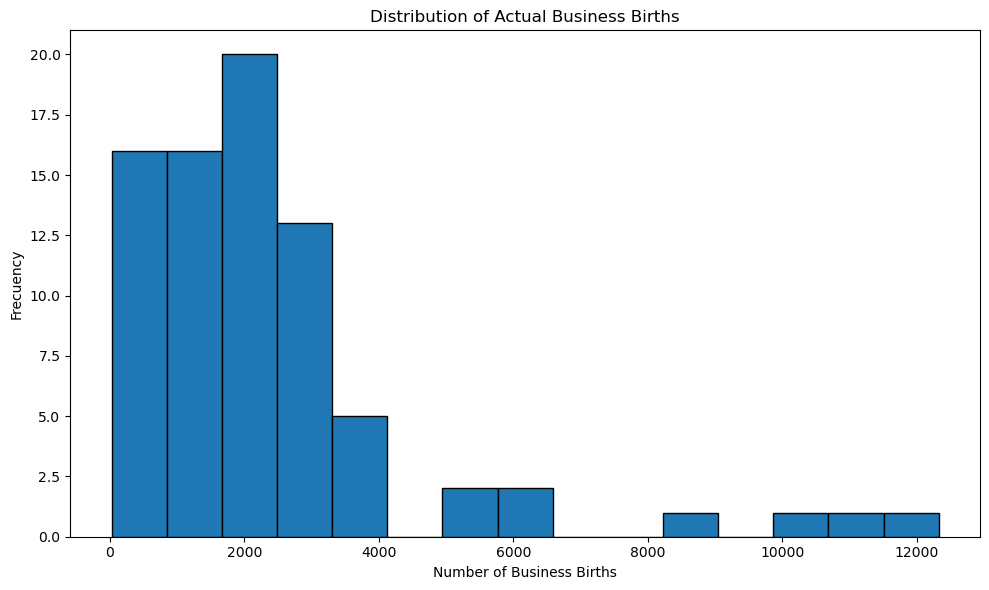

In [233]:
#Examine the distribution of business births

print(poisson_data.describe())

print("\nLowest business births:")
print(poisson_data.nsmallest(5))

print("\nHighest business births:")
print(poisson_data.nlargest(5))

#Visualise the observed data

plt.figure(figsize = (10, 6))

plt.hist(poisson_data, bins = 15, edgecolor = "black")

plt.title("Distribution of Actual Business Births")
plt.xlabel("Number of Business Births")
plt.ylabel("Frecuency")

plt.tight_layout()
plt.show()

The hypothetical Poisson probabilities were calculated
using SciPy's probability mass, cumulative distribution
and survival functions (SciPy, n.d.-c).

In [234]:
#Compare business births across different cohorts

births_by_cohort = (analysis_table.dropna(subset=["Births"]).groupby("Birth cohort", observed=False)["Births"].agg(["count", "mean", "var", "std"]))

births_by_cohort["Variance-to-mean ratio"] = (births_by_cohort["var"] / births_by_cohort["mean"])

display(births_by_cohort)

,count,mean,var,std,Variance-to-mean ratio
Birth cohort,,,,,
2019,15,1612.866667,2.044053e+06,1429.703859,1267.341663
2020,15,2166.466667,4.697585e+06,2167.391384,2168.316495
2021,16,2224.125000,5.971481e+06,2443.661375,2684.867495
2022,16,2836.250000,8.475377e+06,2911.250144,2988.233548
2023,16,2810.062500,7.338508e+06,2708.968130,2611.510715


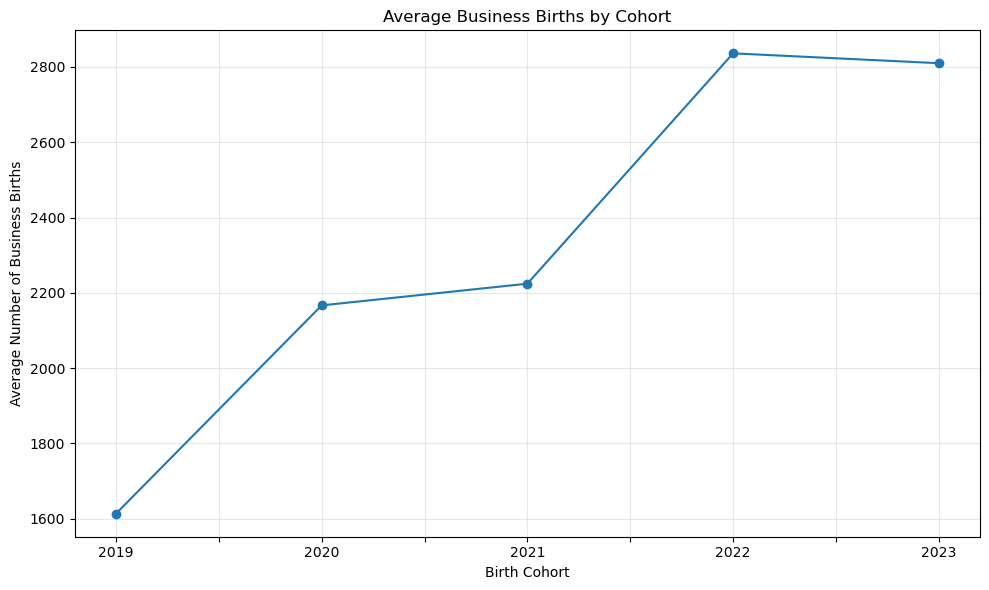

In [235]:
#Average business births by birth cohort

plt.figure(figsize=(10, 6))

births_by_cohort["mean"].plot(kind="line", marker="o")

plt.title("Average Business Births by Cohort")
plt.xlabel("Birth Cohort")
plt.ylabel("Average Number of Business Births")

plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

# Assessment of the Poisson Model:
As lambda increases, the Poisson distribution becomes more symmetric and approaches a Normal distribution. Increasing the number of observations alone does not produce this change. The large fitted lambda supports this theoretical approximation, but it does not resolve the poor fit to the observed birth counts.

# Summary of the Stats analysis
The normal and binomal distributions provided useful estimates of business survival probabilities.

The Poisson distribution was used to analyze business creation, although considerable overdispersion was observed. These results highlight the importance of understanding the assumptions and limitations of each statistical method.

# Conclusions

In summary, we have learned that it is important to analyze information in a clear and objectiv manner, this helps us make informed decisions and better understand the topics that interest us. Ultimately, we must remember that we can always improce and learn more as we face new challenges. The one year survival rate of businesses in Ireland varied across different economic sectors and groups of new enterprises between 2019 and 2023. 

The average survival rate unadjusted by sector and group was 80.59%. The construction sector had the lowest survival rate, whereas the electricity, gas, steam, and air conditioning supply sector had the highest. These differences do not in themselves, explain why such variations happens. A binomial model was used to illustrate the probabilities of survival based on a few simple assumptions. 

The presence of excessive dispersion indicated that a Poisson model with a common rate was not appropriate for the dara on business creation.
Furthermore, a normal distribution approach proved inadequate for representing the observed survival rates. These results underscore the importance of verifying model assumptions. It is also crucial to account for missing data and variations in sectoral coverage when analysis the findings.

In [236]:
#Save the prepared dataset
analysis_table.to_csv("BRA36_prepared_dataset.csv", index=False)

print("Prepared dataset saved.")

Prepared dataset saved.


# References

Central Statistics Office (n.d.) BRA36 – Enterprise Survival
NACE Rev 2 [Dataset]. Available at:
https://data.gov.ie/dataset/bra36-enterprise-survival-nace-rev-2
(Accessed: 20 October 2026).

SciPy (n.d.-a) scipy.stats.binom. SciPy documentation.
Available at:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html
(Accessed: 24 October 2026).

SciPy (n.d.-b) scipy.stats.norm. SciPy documentation.
Available at:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html
(Accessed: 24 October 2026

SciPy (n.d.-c) scipy.stats.poisson. SciPy documentation.
Available at:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html
(Accessed: 24 October 2026).

SciPy (n.d.-d) scipy.stats.probplot. SciPy documentation.
Available at:
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html
(Accessed: 24 October 2026).